## **02_pytorch_classification_exercises** 

1. Make a binary classification dataset with Scikit-Learn's [`make_moons()`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) function.
    * For consistency, the dataset should have 1000 samples and a `random_state=42`.
    * Turn the data into PyTorch tensors. 
	* Split the data into training and test sets using `train_test_split` with 80% training and 20% testing.

In [1]:
# check the device 
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [22]:
from sklearn.datasets import make_moons

# Make 1000 samples 
n_samples = 1000 
RANDOM_SEED = 42

# Create circles
X, y = make_moons(
    n_samples= n_samples,
    noise= 0.07,
    random_state= RANDOM_SEED
)

X[:10], y[:10]

(array([[-0.03341062,  0.4213911 ],
        [ 0.99882703, -0.4428903 ],
        [ 0.88959204, -0.32784256],
        [ 0.34195829, -0.41768975],
        [-0.83853099,  0.53237483],
        [ 0.59906425, -0.28977331],
        [ 0.29009023, -0.2046885 ],
        [-0.03826868,  0.45942924],
        [ 1.61377123, -0.2939697 ],
        [ 0.693337  ,  0.82781911]]),
 array([1, 1, 1, 1, 0, 1, 1, 1, 1, 0]))

In [23]:
# Turn data into a DataFrame
import pandas as pd
data_df = pd.DataFrame({"X0": X[:, 0],
                        "X1": X[:, 1],
                        "y": y})
data_df.head()

,X0,X1,y
0,-0.033411,0.421391,1
1,0.998827,-0.442890,1
2,0.889592,-0.327843,1
3,0.341958,-0.417690,1
4,-0.838531,0.532375,0


In [25]:
# Turn data into tensor 

X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)


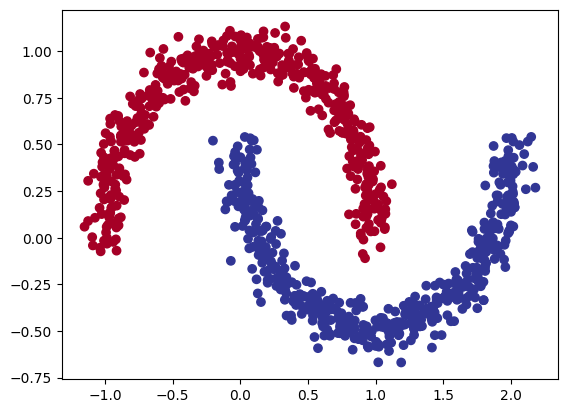

In [24]:
# Visualize the data on a plot
import matplotlib.pyplot as plt
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu);

In [48]:
# Split the data into training and test sets (80% / 20%)
from sklearn.model_selection import train_test_split

# Always follow this order: X_train, X_test, y_train, y_test.
# Using the wrong order can cause shape mismatches in the training loop.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_SEED
)

len(X_train), len(y_train), len(X_test), len(y_test)

(800, 800, 200, 200)

2. Build a model by subclassing `nn.Module` that incorporates non-linear activation functions and is capable of fitting the data you created in 1.
    * Feel free to use any combination of PyTorch layers (linear and non-linear) you want

In [38]:
import torch
from torch import nn

class MoonModelV0(nn.Module):
    def __init__(self, in_features, out_features, hidden_units):
        super().__init__()
        
        self.layer1 = nn.Linear(in_features=in_features, 
                                 out_features=hidden_units)
        self.layer2 = nn.Linear(in_features=hidden_units, 
                                 out_features=hidden_units)
        self.layer3 = nn.Linear(in_features=hidden_units,
                                out_features=out_features)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.layer3(self.relu(self.layer2(self.relu(self.layer1(x)))))

model_0 = MoonModelV0(in_features=2,
                      out_features=1,
                      hidden_units=10).to(device)
model_0

MoonModelV0(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [39]:
# Let's see the parameters 

#model_0.state_dict() 
model_0.layer1.state_dict()

OrderedDict([('weight',
              tensor([[-0.4244,  0.0056],
                      [ 0.3363, -0.4882],
                      [ 0.6867, -0.3533],
                      [-0.1698, -0.1913],
                      [-0.4608, -0.6939],
                      [ 0.3987,  0.1879],
                      [-0.6623, -0.4551],
                      [ 0.6989,  0.2703],
                      [ 0.2837, -0.4231],
                      [-0.3100, -0.1067]])),
             ('bias',
              tensor([-0.1293, -0.4845,  0.0583,  0.0703, -0.0895,  0.0980, -0.2803,  0.1840,
                       0.2667, -0.3725]))])

3. Setup a binary classification compatible loss function and optimizer to use when training the model.

In [40]:
loss_fn = nn.BCEWithLogitsLoss() # sigmoid layer built-in
# loss_fn = nn.BCELoss() # requires sigmoid layer
optimizer = torch.optim.SGD(params=model_0.parameters(), # parameters of model to optimize 
                            lr=0.1) # learning rate

4. Create a training and testing loop to fit the model you created in 2 to the data you created in 1.
    * To measure model accuracy, you can create your own accuracy function or use the accuracy function in [TorchMetrics](https://torchmetrics.readthedocs.io/en/latest/).
    * Train the model for long enough for it to reach over 96% accuracy.
    * The training loop should output progress every 10 epochs of the model's training and test set loss and accuracy.

In [41]:
# before that let's check how the model perform

y_logits = model_0(X_train[:10]).squeeze()
y_pred_probs = torch.sigmoid(y_logits)
y_pred_labels = torch.round(y_pred_probs)
print("Logits :", y_logits)
print("Pred probs:", y_pred_probs)
print("Pred Labels: ", y_pred_labels)

Logits : tensor([0.3131, 0.1289, 0.1663, 0.1664, 0.1478, 0.1509, 0.1581, 0.1413, 0.2243,
        0.1404], grad_fn=<SqueezeBackward0>)
Pred probs: tensor([0.5776, 0.5322, 0.5415, 0.5415, 0.5369, 0.5377, 0.5394, 0.5353, 0.5559,
        0.5350], grad_fn=<SigmoidBackward0>)
Pred Labels:  tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], grad_fn=<RoundBackward0>)


In [18]:
!pip -q install torchmetrics # colab doesn't come with torchmetrics


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [19]:
# First download torchmetrics
%pip install torchmetrics

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [43]:
from torchmetrics import Accuracy
acc_fn = Accuracy(task="multiclass", num_classes=2).to(device) # send accuracy function to device
acc_fn

MulticlassAccuracy()

In [ ]:
torch.manual_seed(RANDOM_SEED)

epochs=1000

# Send data to the device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Loop through the data
for epoch in range(epochs):
  ### Training
  model_0.train()

  # 1. Forward pass
  y_logits = model_0(X_train).squeeze()
  # print(y_logits[:5]) # model raw outputs are "logits"
  y_pred_probs = torch.sigmoid(y_logits)
  y_pred = torch.round(y_pred_probs)

  # 2. Calculaute the loss
  loss = loss_fn(y_logits, y_train) # loss = compare model raw outputs to desired model outputs
  acc = acc_fn(y_pred, y_train.int()) # the accuracy function needs to compare pred labels (not logits) with actual labels

  # 3. Zero the gradients
  optimizer.zero_grad()

  # 4. Loss backward (perform backpropagation)
  loss.backward()

  # 5. Step the optimizer (gradient descent)  
  optimizer.step()

  ### Testing
  model_0.eval() 
  with torch.inference_mode():
    # 1. Forward pass
    test_logits = model_0(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))
    # 2. Caculate the loss/acc
    test_loss = loss_fn(test_logits, y_test)
    test_acc = acc_fn(test_pred, y_test.int()) 

  # Print out what's happening
  if epoch % 100 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.2f} Acc: {acc:.2f} | Test loss: {test_loss:.2f} Test acc: {test_acc:.2f}")

Epoch: 0 | Loss: 0.69 Acc: 0.50 | Test loss: 0.69 Test acc: 0.50
Epoch: 100 | Loss: 0.47 Acc: 0.78 | Test loss: 0.49 Test acc: 0.73
Epoch: 200 | Loss: 0.32 Acc: 0.86 | Test loss: 0.33 Test acc: 0.84
Epoch: 300 | Loss: 0.24 Acc: 0.89 | Test loss: 0.24 Test acc: 0.90
Epoch: 400 | Loss: 0.21 Acc: 0.91 | Test loss: 0.20 Test acc: 0.90
Epoch: 500 | Loss: 0.17 Acc: 0.93 | Test loss: 0.17 Test acc: 0.92
Epoch: 600 | Loss: 0.13 Acc: 0.94 | Test loss: 0.13 Test acc: 0.96
Epoch: 700 | Loss: 0.09 Acc: 0.97 | Test loss: 0.08 Test acc: 0.98
Epoch: 800 | Loss: 0.06 Acc: 0.99 | Test loss: 0.05 Test acc: 1.00
Epoch: 900 | Loss: 0.04 Acc: 0.99 | Test loss: 0.03 Test acc: 1.00
